# Validacao externa dos cinco algoritmos no ano de 2025

Este notebook avalia os cinco algoritmos sobre o ano de 2025, um periodo nunca usado em nenhuma decisao de ajuste, selecao de hiperparametros ou escolha de algoritmo ate este ponto do projeto.
O objetivo e verificar a estabilidade temporal do desempenho de cada algoritmo, comparando diretamente as metricas obtidas no teste de 2024, usado ate aqui como referencia principal, com as metricas obtidas em 2025.
O ano de 2025 tem prevalencia de obito bem mais baixa do que 2024, 2,75 por cento contra 5,23 por cento, o que por si so reduz o valor esperado da AUPRC em 2025 mesmo para um algoritmo com discriminacao identica, ja que a AUPRC de um classificador sem nenhum poder discriminativo e igual a prevalencia observada.
Por isso, alem da comparacao direta das metricas, este notebook tambem compara a razao entre a AUPRC de cada algoritmo e a prevalencia do respectivo ano, uma forma de normalizar a AUPRC pela mudanca de prevalencia e isolar a parte da queda de desempenho que nao se explica simplesmente por haver menos obitos para encontrar em 2025.

Importa as bibliotecas necessarias, inclui a raiz do projeto no caminho de importacao para reutilizar `utils/preprocessamento.py`, e cria o diretorio de saida usado ao longo do notebook.
A tabela comparativa final e salva em `analysis/results_avaliacao/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from utils import preprocessamento

DIRETORIO_METRICAS = PROJECT_ROOT / "output" / "metricas"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_avaliacao"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "avaliacao"
DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]

Carrega, para cada um dos cinco algoritmos, as predicoes de probabilidade e o alvo real do teste de 2024 e da validacao externa de 2025, e confirma a prevalencia observada de obito em cada um dos dois anos.

In [2]:
predicoes_teste2024 = {
    algoritmo: pd.read_parquet(DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024.parquet")
    for algoritmo in ALGORITMOS
}
predicoes_val2025 = {
    algoritmo: pd.read_parquet(DIRETORIO_METRICAS / f"{algoritmo}_predicoes_val2025.parquet")
    for algoritmo in ALGORITMOS
}

prevalencia_teste2024 = predicoes_teste2024[ALGORITMOS[0]]["obito"].mean()
prevalencia_val2025 = predicoes_val2025[ALGORITMOS[0]]["obito"].mean()

(
    len(predicoes_teste2024[ALGORITMOS[0]]),
    predicoes_teste2024[ALGORITMOS[0]]["obito"].sum(),
    prevalencia_teste2024,
    len(predicoes_val2025[ALGORITMOS[0]]),
    predicoes_val2025[ALGORITMOS[0]]["obito"].sum(),
    prevalencia_val2025,
)

(3978,
 np.int64(208),
 np.float64(0.05228758169934641),
 3241,
 np.int64(89),
 np.float64(0.02746066029003394))

Calcula AUPRC, ROC-AUC e Brier Score de cada algoritmo nos dois anos, usando `avaliar_predicoes` de `utils/preprocessamento.py`, e organiza o resultado numa tabela longa com uma linha por combinacao de algoritmo e metrica.

In [3]:
linhas_comparacao = []
for algoritmo in ALGORITMOS:
    metricas_teste2024 = preprocessamento.avaliar_predicoes(
        predicoes_teste2024[algoritmo]["obito"], predicoes_teste2024[algoritmo]["probabilidade_predita"]
    )
    metricas_val2025 = preprocessamento.avaliar_predicoes(
        predicoes_val2025[algoritmo]["obito"], predicoes_val2025[algoritmo]["probabilidade_predita"]
    )

    for nome_metrica in ["auprc", "roc_auc", "brier_score"]:
        valor_teste2024 = metricas_teste2024[nome_metrica]
        valor_val2025 = metricas_val2025[nome_metrica]
        linhas_comparacao.append(
            {
                "algoritmo": algoritmo,
                "metrica": nome_metrica,
                "teste2024": valor_teste2024,
                "val2025": valor_val2025,
                "diferenca_absoluta": valor_val2025 - valor_teste2024,
                "diferenca_percentual": (valor_val2025 - valor_teste2024) / valor_teste2024 * 100,
            }
        )

tabela_comparacao_2024_vs_2025 = pd.DataFrame(linhas_comparacao)
tabela_comparacao_2024_vs_2025

,algoritmo,metrica,teste2024,val2025,diferenca_absoluta,diferenca_percentual
0,regressao_logistica,auprc,0.206604,0.136544,-0.070060,-33.910267
1,regressao_logistica,roc_auc,0.810633,0.817565,0.006932,0.855185
2,regressao_logistica,brier_score,0.239320,0.243486,0.004166,1.740712
3,arvore_decisao,auprc,0.120433,0.076631,-0.043802,-36.370546
4,arvore_decisao,roc_auc,0.714876,0.735123,0.020246,2.832135
5,arvore_decisao,brier_score,0.239224,0.234581,-0.004643,-1.940775
6,random_forest,auprc,0.187008,0.122927,-0.064081,-34.266519
7,random_forest,roc_auc,0.804966,0.802052,-0.002914,-0.362000
8,random_forest,brier_score,0.072640,0.060460,-0.012180,-16.767844
9,xgboost,auprc,0.196245,0.115276,-0.080969,-41.259151


Calcula, para cada algoritmo, a razao entre a AUPRC e a prevalencia observada de obito no respectivo ano, chamada aqui de ganho sobre a prevalencia.
Essa razao normaliza a AUPRC pelo piso teorico de um classificador sem nenhum poder discriminativo, cuja AUPRC esperada e igual a propria prevalencia, o que permite comparar a capacidade relativa de discriminacao entre os dois anos apesar da queda de prevalencia de obito de 5,23 para 2,75 por cento.
O resultado e adicionado a tabela comparativa como linhas de uma metrica adicional, `ganho_auprc_sobre_prevalencia`.

In [4]:
linhas_ganho_sobre_prevalencia = []
for algoritmo in ALGORITMOS:
    auprc_teste2024 = tabela_comparacao_2024_vs_2025.loc[
        (tabela_comparacao_2024_vs_2025["algoritmo"] == algoritmo)
        & (tabela_comparacao_2024_vs_2025["metrica"] == "auprc"),
        "teste2024",
    ].iloc[0]
    auprc_val2025 = tabela_comparacao_2024_vs_2025.loc[
        (tabela_comparacao_2024_vs_2025["algoritmo"] == algoritmo)
        & (tabela_comparacao_2024_vs_2025["metrica"] == "auprc"),
        "val2025",
    ].iloc[0]

    ganho_teste2024 = auprc_teste2024 / prevalencia_teste2024
    ganho_val2025 = auprc_val2025 / prevalencia_val2025

    linhas_ganho_sobre_prevalencia.append(
        {
            "algoritmo": algoritmo,
            "metrica": "ganho_auprc_sobre_prevalencia",
            "teste2024": ganho_teste2024,
            "val2025": ganho_val2025,
            "diferenca_absoluta": ganho_val2025 - ganho_teste2024,
            "diferenca_percentual": (ganho_val2025 - ganho_teste2024) / ganho_teste2024 * 100,
        }
    )

tabela_comparacao_2024_vs_2025 = pd.concat(
    [tabela_comparacao_2024_vs_2025, pd.DataFrame(linhas_ganho_sobre_prevalencia)], ignore_index=True
)

tabela_comparacao_2024_vs_2025.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "comparacao_2024_vs_2025.csv", index=False
)
tabela_comparacao_2024_vs_2025.sort_values(["metrica", "algoritmo"]).reset_index(drop=True)

,algoritmo,metrica,teste2024,val2025,diferenca_absoluta,diferenca_percentual
0,arvore_decisao,auprc,0.120433,0.076631,-0.043802,-36.370546
1,lightgbm,auprc,0.168298,0.113570,-0.054728,-32.518603
2,random_forest,auprc,0.187008,0.122927,-0.064081,-34.266519
3,regressao_logistica,auprc,0.206604,0.136544,-0.070060,-33.910267
4,xgboost,auprc,0.196245,0.115276,-0.080969,-41.259151
5,arvore_decisao,brier_score,0.239224,0.234581,-0.004643,-1.940775
6,lightgbm,brier_score,0.140349,0.128512,-0.011837,-8.433912
7,random_forest,brier_score,0.072640,0.060460,-0.012180,-16.767844
8,regressao_logistica,brier_score,0.239320,0.243486,0.004166,1.740712
9,xgboost,brier_score,0.189623,0.181436,-0.008187,-4.317622


Gera um grafico de barras comparando a AUPRC e o ROC-AUC de cada algoritmo entre o teste de 2024 e a validacao externa de 2025, lado a lado, para visualizar diretamente a magnitude da queda de desempenho entre os dois anos.
O grafico e salvo em `analysis/plots/avaliacao/comparacao_metricas_2024_vs_2025.png`.

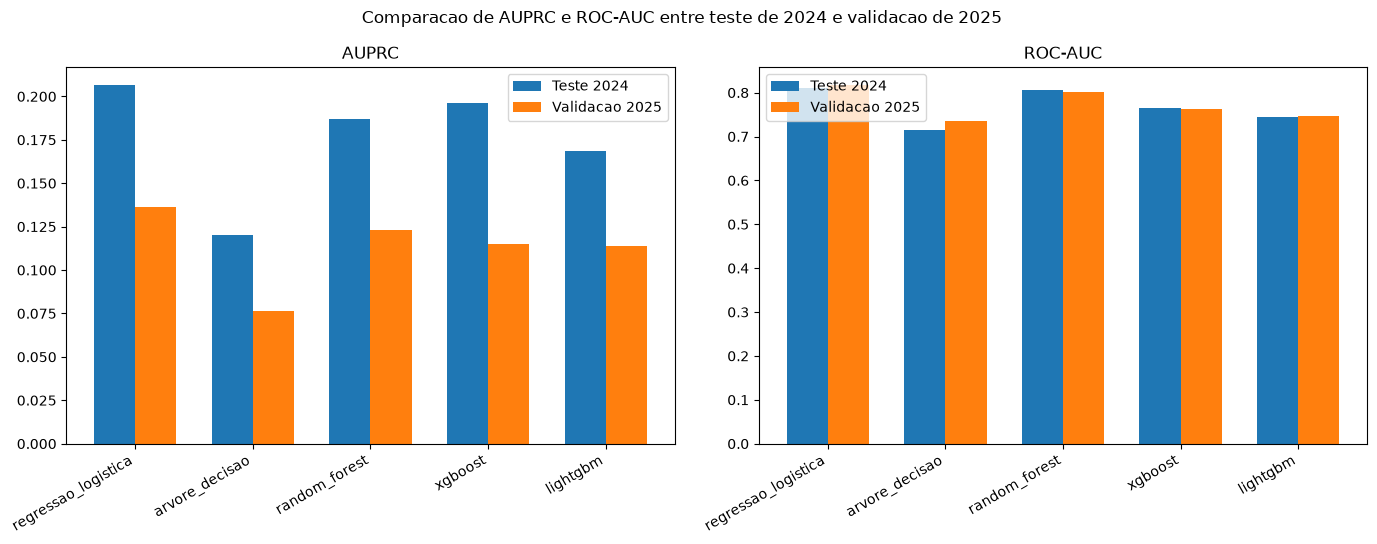

In [5]:
figura, eixos = plt.subplots(1, 2, figsize=(14, 5.5))

largura_barra = 0.35
posicoes = np.arange(len(ALGORITMOS))

for eixo_atual, nome_metrica, titulo in zip(eixos, ["auprc", "roc_auc"], ["AUPRC", "ROC-AUC"]):
    tabela_metrica = tabela_comparacao_2024_vs_2025[
        tabela_comparacao_2024_vs_2025["metrica"] == nome_metrica
    ].set_index("algoritmo").loc[ALGORITMOS]

    eixo_atual.bar(posicoes - largura_barra / 2, tabela_metrica["teste2024"], largura_barra, label="Teste 2024")
    eixo_atual.bar(posicoes + largura_barra / 2, tabela_metrica["val2025"], largura_barra, label="Validacao 2025")
    eixo_atual.set_xticks(posicoes)
    eixo_atual.set_xticklabels(ALGORITMOS, rotation=30, ha="right")
    eixo_atual.set_title(titulo)
    eixo_atual.legend()

figura.suptitle("Comparacao de AUPRC e ROC-AUC entre teste de 2024 e validacao de 2025")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "comparacao_metricas_2024_vs_2025.png", dpi=150)
plt.show()

## Sintese dos achados

Nenhum dos cinco algoritmos mostra uma queda de desempenho acentuada entre o teste de 2024 e a validacao externa de 2025, um quadro bem mais estavel do que a AUPRC absoluta sozinha sugere.
A AUPRC absoluta cai para os cinco algoritmos, entre 32,5 por cento no LightGBM e 41,3 por cento no XGBoost, mas essa queda e menor, em todos os casos, do que a propria reducao de prevalencia de obito entre os dois anos, de 5,23 para 2,75 por cento, uma reducao relativa de 47,5 por cento, o que explica a maior parte da queda de AUPRC sem indicar perda real de capacidade discriminativa.
O ganho de AUPRC sobre a prevalencia, que isola a parte da AUPRC que nao se explica apenas pela prevalencia, aumenta de 2024 para 2025 nos cinco algoritmos, o que confirma que a capacidade relativa de discriminacao de nenhum deles se deteriora entre os dois anos.
O aumento vai de 3,58 para 4,48 vezes a prevalencia no Random Forest, de 2,30 para 2,79 vezes na Arvore de Decisao, de 3,95 para 4,97 vezes na Regressao Logistica, e de 3,22 para 4,14 vezes no LightGBM, um aumento relativo entre 21 e 28 por cento nesses quatro algoritmos.
O XGBoost tambem melhora por essa medida, de 3,75 para 4,20 vezes a prevalencia, mas com um aumento relativo de apenas 11,8 por cento, bem abaixo dos demais, o que o torna o algoritmo cuja vantagem relativa sobre a prevalencia menos se expande entre os dois anos, ainda que tambem sem piorar.
O ROC-AUC confirma esse quadro geral de estabilidade, com variacoes bem menores do que as da AUPRC absoluta em todos os casos.
O Random Forest tem a maior queda de ROC-AUC entre os cinco algoritmos, de 0,805 para 0,802, uma queda de apenas 0,4 por cento, seguido de perto pelo XGBoost, de 0,766 para 0,764, uma queda de 0,3 por cento.
Os outros tres algoritmos melhoram de forma leve o ROC-AUC na validacao de 2025: o LightGBM, de 0,746 para 0,748, um aumento de 0,3 por cento, a Regressao Logistica, de 0,811 para 0,818, um aumento de 0,9 por cento, e a Arvore de Decisao, de 0,715 para 0,735, o maior aumento entre os cinco, de 2,8 por cento.
O Brier Score melhora na validacao de 2025 para quatro dos cinco algoritmos, com a maior melhora no Random Forest, de 0,073 para 0,060, uma queda de 16,8 por cento, e piora de forma minima apenas na Regressao Logistica, de 0,239 para 0,243, um aumento de 1,7 por cento.
Como no teste de 2024, essa melhora generalizada do Brier Score e esperada pela queda de prevalencia entre os dois anos, e nao deve ser lida como evidencia de melhora real de desempenho.
Em conjunto, estes resultados indicam que o desempenho dos cinco algoritmos e estavel, ou mesmo relativamente melhor, entre o teste de 2024 e a validacao externa de 2025, sem nenhum caso de degradacao acentuada por qualquer uma das medidas consideradas aqui.
O XGBoost e o Random Forest sao os dois algoritmos cuja estabilidade e menos favoravel entre os dois anos, o XGBoost por ter o menor aumento relativo no ganho de AUPRC sobre a prevalencia, e o Random Forest por ter a maior queda de ROC-AUC entre os cinco, ainda que pequena, enquanto a Arvore de Decisao, a Regressao Logistica e o LightGBM mostram o quadro mais favoravel de generalizacao entre os dois anos por essas duas medidas.